# FarmTech Solutions — Fase 5: Machine Learning na Cabeça

**Grupo:**
- Jonattas Felipe — RM572692
- Natanael Filho — RM572474
- Pedro Henrique — RM571394
- Andrews Oliveira — RM572311
**Disciplina:** Inteligência Artificial — FIAP
**Entrega 1:** Machine Learning (Regressão Supervisionada + Clusterização)

---

## Objetivo

Este notebook analisa a base `crop_yield.csv`, fornecida pela FarmTech Solutions, contendo variáveis
climáticas e de solo (precipitação, umidade específica, umidade relativa e temperatura) relacionadas
ao rendimento (*yield*) de quatro culturas agrícolas: **Cocoa beans, Oil palm fruit, Rice paddy e
Rubber natural**.

O trabalho está dividido em três partes:

1. **Análise Exploratória de Dados (EDA)** — entender a distribuição, relações e qualidade dos dados.
2. **Aprendizado Não Supervisionado (Clusterização)** — identificar tendências de produtividade e
   possíveis *outliers* nos dados, sem usar o rótulo de rendimento diretamente.
3. **Aprendizado Supervisionado (Regressão)** — treinar e comparar cinco algoritmos diferentes para
   prever o rendimento da safra a partir das condições climáticas.

> **Como usar este notebook:** execute as células em ordem, de cima para baixo (`Kernel > Restart & Run All`).


## Preparação: VS Code (.venv) e Google Colab

A instalação usa apenas `pip` e não requer GPU.

### VS Code com .venv
Abra a pasta do projeto, com `requirements.txt` e `crop_yield.csv` ao lado deste notebook. No terminal da pasta, crie o ambiente virtual e instale as dependências. Em Linux/macOS:

```bash
python3 -m venv .venv
.venv/bin/python -m pip install -r requirements.txt
```

No Windows:

```powershell
python -m venv .venv
.venv\Scripts\python.exe -m pip install -r requirements.txt
```

No seletor de kernel do notebook, escolha **Ambientes Python > .venv** e execute todas as células. Não é necessário ativar o ambiente no terminal.

### Google Colab
Abra este `.ipynb` no Colab e use **Ambiente de execução > Executar tudo**. A próxima célula instala as dependências com `pip` na própria sessão, sem precisar enviar `requirements.txt` nem montar o Drive. Na célula de dados, selecione o arquivo original `crop_yield.csv` quando solicitado; se ele já estiver na sessão, o upload será dispensado. Os arquivos do Colab são temporários: envie novamente após criar uma nova sessão.

A instalação requer internet na primeira execução; nas seguintes, o `pip` apenas confirma que os pacotes já estão presentes.

In [ ]:
import subprocess
import sys
from pathlib import Path

DEPENDENCIAS = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn"]

NO_COLAB = "google.colab" in sys.modules
ambiente = "Google Colab" if NO_COLAB else "VS Code (.venv)"

if Path("requirements.txt").exists():
    alvo = ["-r", "requirements.txt"]
else:
    alvo = DEPENDENCIAS

print(f"Ambiente: {ambiente} | Python {sys.version.split()[0]}")
print("Instalando dependências com pip...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *alvo])
print("Ambiente preparado.")

In [2]:
# Bibliotecas de manipulação de dados e visualização
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bibliotecas de Machine Learning (scikit-learn)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import silhouette_score

# Modelos de regressão (5 algoritmos distintos, conforme solicitado)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configurações visuais
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42  # semente fixa para reprodutibilidade


## 1. Análise Exploratória de Dados (EDA)

Nesta etapa vamos carregar a base, entender sua estrutura, checar qualidade dos dados
(valores nulos, duplicados) e explorar as distribuições e relações entre as variáveis.


In [ ]:
# Carregamento da base de dados: crop_yield.csv na mesma pasta do notebook
from pathlib import Path

caminho_dados = Path('crop_yield.csv')
if not caminho_dados.is_file() and NO_COLAB:
    from google.colab import files

    print('Selecione o arquivo original crop_yield.csv fornecido na atividade.')
    enviados = files.upload()
    if 'crop_yield.csv' not in enviados:
        raise FileNotFoundError('Envie crop_yield.csv e execute esta célula novamente.')

df = pd.read_csv(caminho_dados)
colunas_esperadas = [
    'Crop', 'Precipitation (mm day-1)',
    'Specific Humidity at 2 Meters (g/kg)',
    'Relative Humidity at 2 Meters (%)', 'Temperature at 2 Meters (C)', 'Yield',
]
faltantes = set(colunas_esperadas) - set(df.columns)
if faltantes:
    raise ValueError(f'CSV incompatível. Colunas ausentes: {sorted(faltantes)}')

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()

In [4]:
# Estrutura e tipos de dados
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Crop                                  156 non-null    object 
 1   Precipitation (mm day-1)              156 non-null    float64
 2   Specific Humidity at 2 Meters (g/kg)  156 non-null    float64
 3   Relative Humidity at 2 Meters (%)     156 non-null    float64
 4   Temperature at 2 Meters (C)           156 non-null    float64
 5   Yield                                 156 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 7.4+ KB


In [5]:
# Checagem de qualidade: valores nulos e linhas duplicadas
print("Valores nulos por coluna:")
print(df.isna().sum())
print(f"\nLinhas duplicadas: {df.duplicated().sum()}")


Valores nulos por coluna:
Crop                                    0
Precipitation (mm day-1)                0
Specific Humidity at 2 Meters (g/kg)    0
Relative Humidity at 2 Meters (%)       0
Temperature at 2 Meters (C)             0
Yield                                   0
dtype: int64

Linhas duplicadas: 0


In [6]:
# Quantidade de registros por cultura
df["Crop"].value_counts()


Crop
Cocoa, beans       39
Oil palm fruit     39
Rice, paddy        39
Rubber, natural    39
Name: count, dtype: int64

In [7]:
# Estatísticas descritivas das variáveis numéricas
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Precipitation (mm day-1),156.00,"2,486.50",289.46,"1,934.62","2,302.99","2,424.55","2,718.08","3,085.79"
Specific Humidity at 2 Meters (g/kg),156.00,18.20,0.29,17.54,18.03,18.27,18.40,18.70
Relative Humidity at 2 Meters (%),156.00,84.74,1.00,82.11,84.12,84.85,85.51,86.10
Temperature at 2 Meters (C),156.00,26.18,0.26,25.56,26.02,26.13,26.30,26.81
Yield,156.00,"56,153.10","70,421.96","5,249.00","8,327.75","18,871.00","67,518.75","203,399.00"


### 1.1 Distribuição das variáveis numéricas

Histogramas para visualizar a forma da distribuição de cada variável climática e do rendimento.


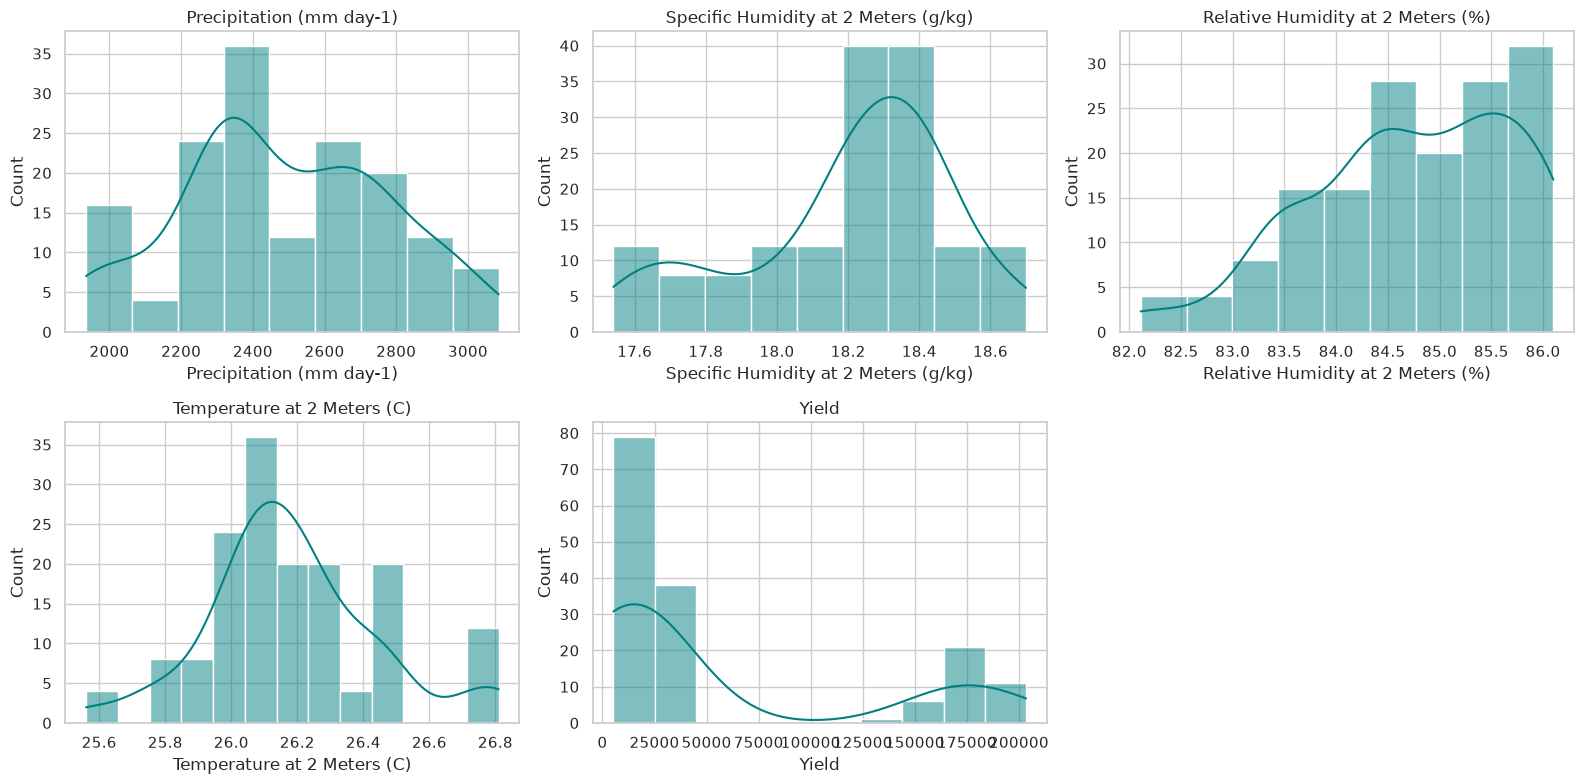

In [8]:
num_cols = [
    "Precipitation (mm day-1)",
    "Specific Humidity at 2 Meters (g/kg)",
    "Relative Humidity at 2 Meters (%)",
    "Temperature at 2 Meters (C)",
    "Yield",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color="teal")
    axes[i].set_title(col)
axes[-1].axis("off")  # subplot sobrando (5 variáveis em grade 2x3)
plt.tight_layout()
plt.show()


### 1.2 Rendimento por cultura

Cada cultura tem uma escala de produtividade muito diferente (ex: arroz produz em toneladas/ha
numa faixa distinta da borracha natural). Vamos visualizar isso com boxplots.


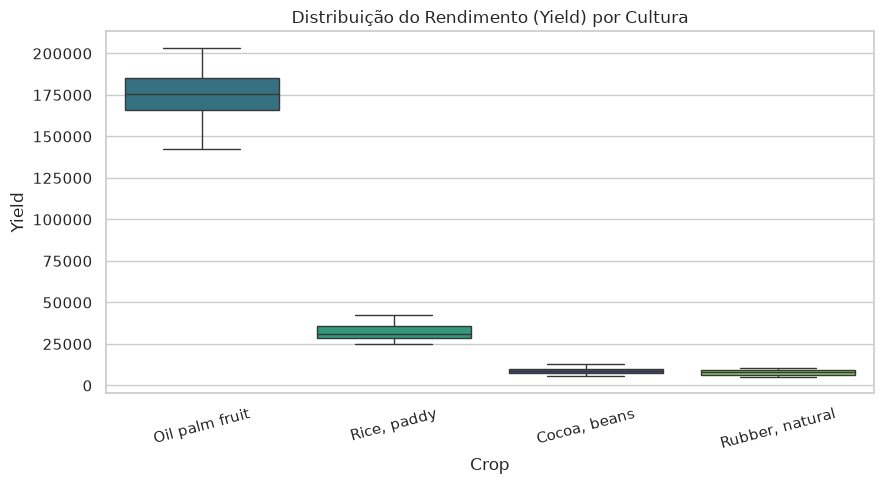

In [9]:
plt.figure(figsize=(9, 5))
order = df.groupby("Crop")["Yield"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Crop", y="Yield", order=order, hue="Crop", palette="viridis", legend=False)
plt.title("Distribuição do Rendimento (Yield) por Cultura")
plt.xticks(rotation=15)
plt.ylabel("Yield")
plt.tight_layout()
plt.show()


### 1.3 Correlação entre as variáveis

Matriz de correlação de Pearson entre as variáveis numéricas, para identificar quais condições
climáticas mais se relacionam com o rendimento.


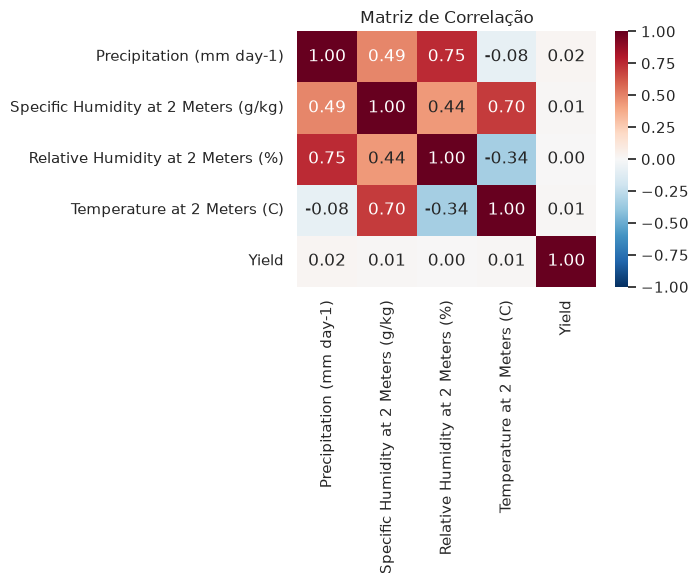

In [10]:
plt.figure(figsize=(7, 6))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matriz de Correlação")
plt.tight_layout()
plt.show()


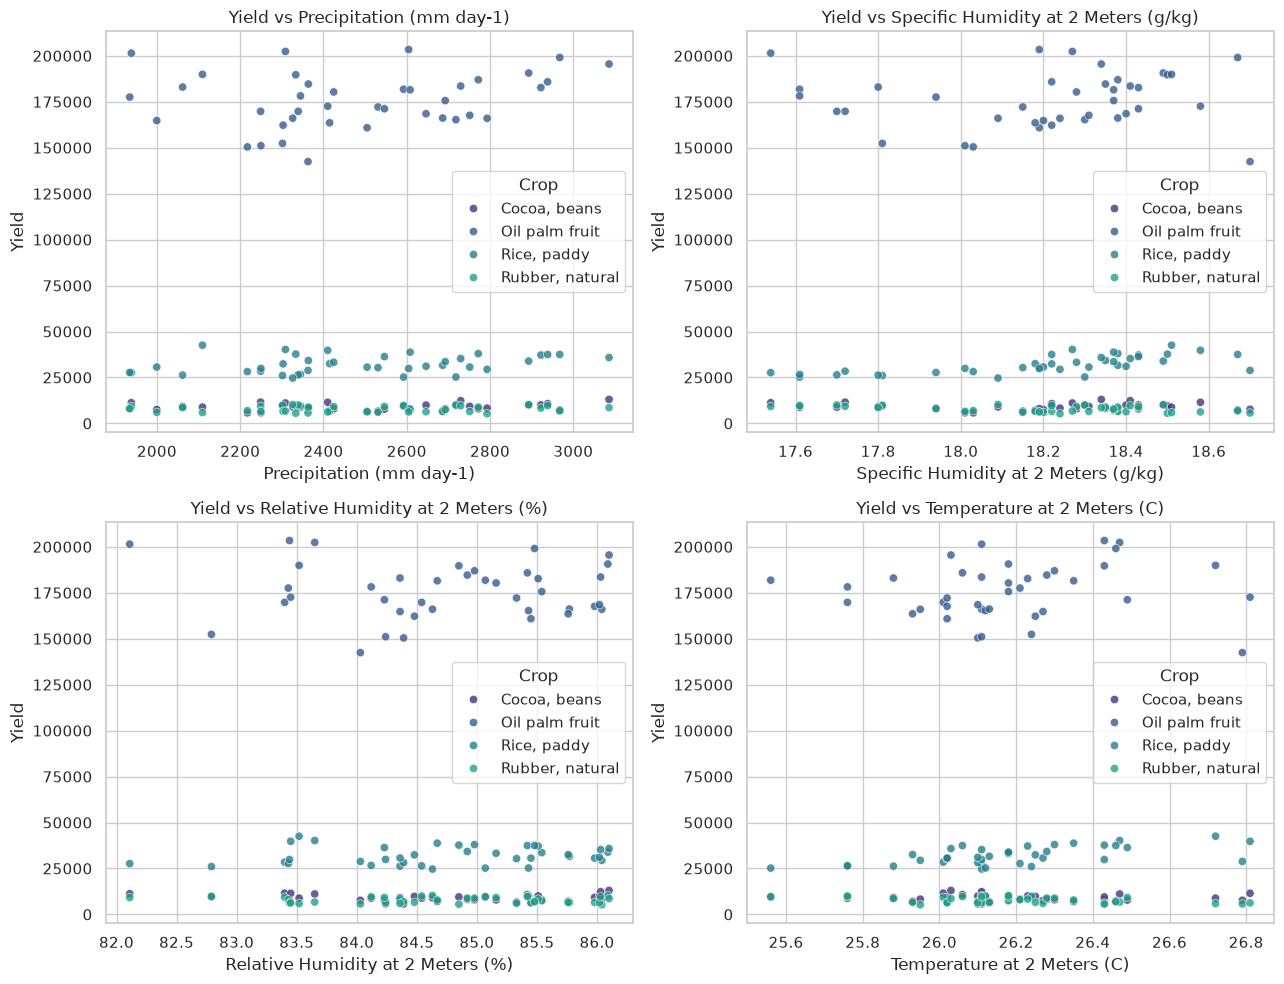

In [11]:
# Relação entre cada variável climática e o rendimento, separado por cultura
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.flatten()
features_clima = num_cols[:-1]
for i, col in enumerate(features_clima):
    sns.scatterplot(data=df, x=col, y="Yield", hue="Crop", ax=axes[i], alpha=0.8)
    axes[i].set_title(f"Yield vs {col}")
plt.tight_layout()
plt.show()


**Observações da EDA (a preencher/ajustar pelo grupo após rodar o notebook):**

- O rendimento (`Yield`) tem escalas muito diferentes entre as culturas, o que sugere que o tipo de
  cultura é a variável mais determinante do rendimento — mais do que as variações climáticas dentro
  de uma mesma cultura.
- As variáveis climáticas (precipitação, umidade e temperatura) têm faixas de variação relativamente
  estreitas dentro de cada cultura, indicando que os dados foram provavelmente coletados nas regiões
  típicas de cultivo de cada produto.
- A matriz de correlação ajuda a identificar quais variáveis têm relação linear mais forte com o
  rendimento — isso será relevante ao interpretar os coeficientes do modelo de Regressão Linear.


## 2. Aprendizado Não Supervisionado: Clusterização e Outliers

Nesta etapa buscamos identificar **tendências de produtividade** por meio de clusterização
(agrupamento), sem usar rótulos, e detectar **cenários discrepantes (outliers)** nos dados.

Vamos usar **K-Means** sobre as variáveis numéricas padronizadas, escolhendo o número de clusters (k)
pelo método do cotovelo (*elbow method*) e validando com o coeficiente de silhueta.


In [12]:
# Seleciona as variáveis numéricas para a clusterização e padroniza (média 0, desvio 1)
X_cluster = df[num_cols].copy()

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)


### 2.1 Escolha do número de clusters (Método do Cotovelo + Silhueta)

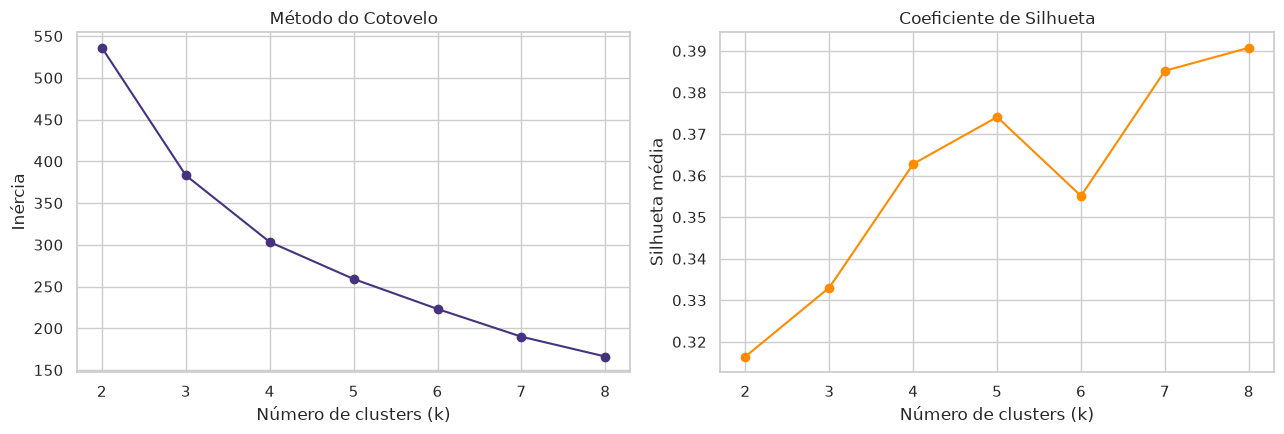

Melhor k pela silhueta: 8


In [13]:
inertias = []
sil_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = km.fit_predict(X_cluster_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_cluster_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_range), inertias, marker="o")
axes[0].set_title("Método do Cotovelo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia")

axes[1].plot(list(k_range), sil_scores, marker="o", color="darkorange")
axes[1].set_title("Coeficiente de Silhueta")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhueta média")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Melhor k pela silhueta: {best_k}")


### 2.2 Aplicação do K-Means com o k escolhido

In [14]:
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_cluster_scaled).astype(str)

df["Cluster"].value_counts().sort_index()


Cluster
0    17
1    24
2    30
3    12
4    11
5    11
6    39
7    12
Name: count, dtype: int64

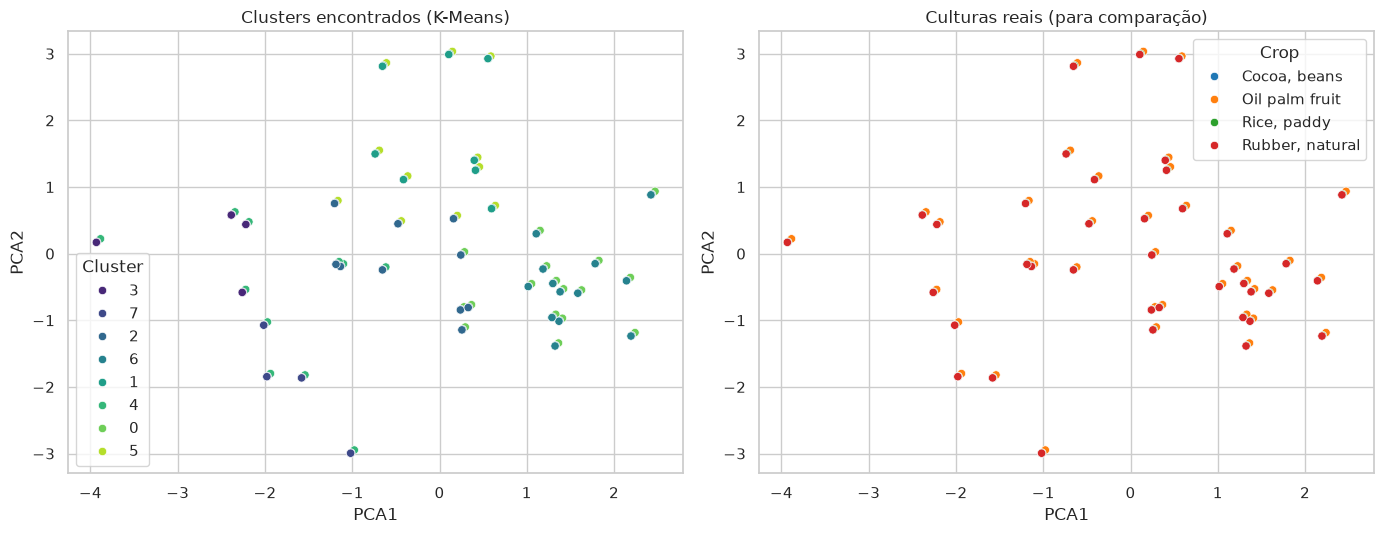

Variância explicada pelos 2 componentes: 74.8%


In [15]:
# Redução de dimensionalidade (PCA) apenas para visualizar os clusters em 2D
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_cluster_scaled)
df["PCA1"], df["PCA2"] = coords[:, 0], coords[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Cluster", palette="viridis", ax=axes[0])
axes[0].set_title("Clusters encontrados (K-Means)")

sns.scatterplot(data=df, x="PCA1", y="PCA2", hue="Crop", palette="tab10", ax=axes[1])
axes[1].set_title("Culturas reais (para comparação)")
plt.tight_layout()
plt.show()

print(f"Variância explicada pelos 2 componentes: {pca.explained_variance_ratio_.sum():.1%}")


In [16]:
# Rendimento médio por cluster: ajuda a interpretar a "tendência de produtividade" de cada grupo
df.groupby("Cluster")[num_cols].mean()


,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C),Yield
Cluster,,,,,
0,"2,733.52",18.34,85.65,26.12,"177,074.18"
1,"2,410.39",18.44,83.98,26.56,"17,456.38"
2,"2,333.41",18.17,84.87,26.13,"15,149.97"
3,"2,105.88",17.75,82.93,26.14,"15,562.08"
4,"2,232.22",17.81,83.92,25.99,"171,039.91"
5,"2,359.02",18.39,84.15,26.48,"178,607.55"
6,"2,814.98",18.38,85.72,26.14,"17,044.28"
7,"2,334.49",17.68,84.52,25.74,"14,881.33"


In [17]:
# Cruzamento Cluster x Cultura: os clusters encontrados coincidem com as culturas reais?
pd.crosstab(df["Cluster"], df["Crop"])


Crop,"Cocoa, beans",Oil palm fruit,"Rice, paddy","Rubber, natural"
Cluster,,,,
0,0,17,0,0
1,8,0,8,8
2,10,0,10,10
3,4,0,4,4
4,0,11,0,0
5,0,11,0,0
6,13,0,13,13
7,4,0,4,4


### 2.3 Detecção de Outliers (cenários discrepantes)

Usamos o algoritmo **Isolation Forest**, adequado para detectar anomalias multivariadas, combinado
com uma checagem visual via boxplot (regra do IQR) por variável.


In [18]:
# Isolation Forest: contamination=0.05 assume que ~5% dos dados podem ser outliers
iso_forest = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
df["Outlier"] = iso_forest.fit_predict(X_cluster_scaled)
df["Outlier"] = df["Outlier"].map({1: "Normal", -1: "Outlier"})

print(df["Outlier"].value_counts())
df[df["Outlier"] == "Outlier"]


Outlier
Normal     148
Outlier      8
Name: count, dtype: int64


,Crop,Precipitation (mm day-1),Specific Humidity at 2 Meters (g/kg),Relative Humidity at 2 Meters (%),Temperature at 2 Meters (C),Yield,Cluster,PCA1,PCA2,Outlier
40,Oil palm fruit,"1,938.42",17.54,82.11,26.11,201436,4,-3.88,0.22,Outlier
42,Oil palm fruit,"2,592.35",17.61,85.07,25.56,181826,4,-0.98,-2.95,Outlier
56,Oil palm fruit,"2,362.80",18.70,84.03,26.79,142425,5,0.59,2.96,Outlier
72,Oil palm fruit,"2,604.59",18.19,83.44,26.43,203399,5,-0.36,1.17,Outlier
74,Oil palm fruit,"2,410.13",18.58,83.45,26.81,172601,5,0.15,3.03,Outlier
75,Oil palm fruit,"2,967.41",18.67,85.48,26.46,199074,0,2.47,0.94,Outlier
77,Oil palm fruit,"2,109.34",18.51,83.52,26.72,189896,5,-0.61,2.86,Outlier
79,"Rice, paddy","1,938.42",17.54,82.11,26.11,27619,3,-3.93,0.17,Outlier


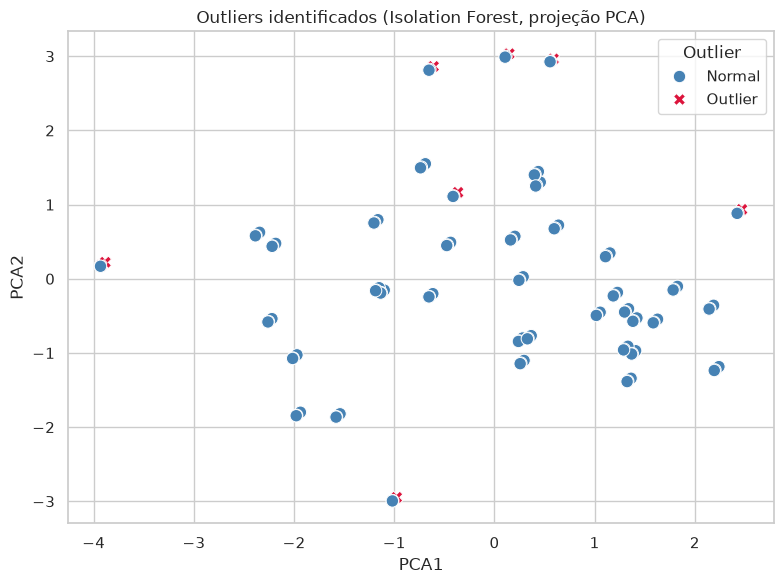

In [19]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x="PCA1", y="PCA2", hue="Outlier",
    palette={"Normal": "steelblue", "Outlier": "crimson"},
    style="Outlier", s=80,
)
plt.title("Outliers identificados (Isolation Forest, projeção PCA)")
plt.tight_layout()
plt.show()


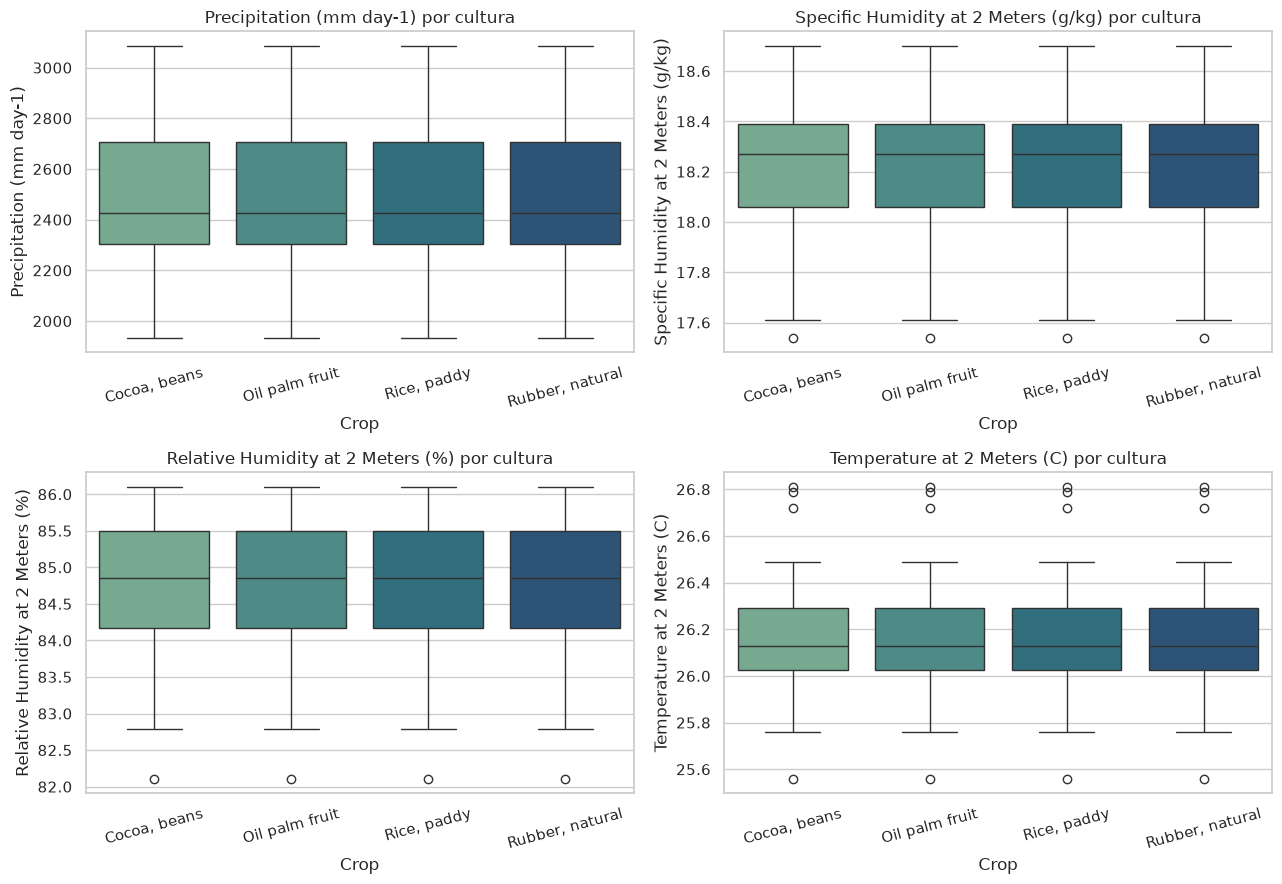

In [20]:
# Checagem complementar por variável, usando a regra do IQR, agrupado por cultura
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
for i, col in enumerate(features_clima):
    sns.boxplot(data=df, x="Crop", y=col, ax=axes[i], hue="Crop", palette="crest", legend=False)
    axes[i].set_title(f"{col} por cultura")
    axes[i].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


**Observações da Clusterização (a ajustar pelo grupo):**

- O número de clusters escolhido pelo coeficiente de silhueta reflete a estrutura natural dos dados.
- A comparação entre os clusters encontrados e as culturas reais (crosstab) mostra o quanto o
  agrupamento não supervisionado, baseado apenas em variáveis climáticas, consegue "recuperar"
  a separação real por tipo de cultura — o que indica que o clima por si só é um bom preditor do
  tipo de cultivo típico de cada região.
- Os registros sinalizados como *outliers* pelo Isolation Forest representam combinações incomuns
  de clima e rendimento (por exemplo, alta precipitação com baixo rendimento, ou vice-versa) e
  merecem investigação antes de decisões de negócio, pois podem indicar erros de sensor ou eventos
  climáticos atípicos (secas, geadas, etc.).


## 3. Aprendizado Supervisionado: Modelos Preditivos de Rendimento

Agora vamos treinar **cinco modelos de regressão diferentes** para prever o `Yield` a partir das
variáveis climáticas e da cultura, seguindo boas práticas: separação treino/teste, padronização
quando necessário, e avaliação com métricas apropriadas ao problema (MAE, RMSE e R²).

Os cinco algoritmos utilizados são:

1. **Regressão Linear** — modelo base, linear, interpretável.
2. **Árvore de Decisão (Decision Tree Regressor)** — modelo não linear, baseado em regras.
3. **Random Forest Regressor** — ensemble de árvores, reduz overfitting.
4. **K-Nearest Neighbors (KNN) Regressor** — baseado em similaridade entre exemplos.
5. **Support Vector Regressor (SVR)** — baseado em margens de tolerância (kernel RBF).


In [21]:
# Features (X) e alvo (y). "Crop" é categórica e precisa ser codificada (One-Hot Encoding).
feature_cols = ["Crop"] + features_clima
X = df[feature_cols]
y = df["Yield"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")


Treino: 124 amostras | Teste: 32 amostras


In [22]:
# Pré-processamento: One-Hot Encoding para "Crop" + padronização das variáveis numéricas.
# Usamos ColumnTransformer dentro de um Pipeline para evitar vazamento de dados (data leakage):
# o scaler/encoder é ajustado (fit) somente com dados de treino.
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["Crop"]),
        ("num", StandardScaler(), features_clima),
    ]
)


In [23]:
# Definição dos 5 modelos de regressão a serem comparados
models = {
    "Regressão Linear": LinearRegression(),
    "Árvore de Decisão": DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=5),
    "Random Forest": RandomForestRegressor(random_state=RANDOM_STATE, n_estimators=300),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "SVR (kernel RBF)": SVR(kernel="rbf", C=100, epsilon=0.1),
}

results = []
predictions = {}

for name, model in models.items():
    # Cada modelo roda dentro do mesmo pipeline de pré-processamento, garantindo consistência
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({"Modelo": name, "MAE": mae, "RMSE": rmse, "R²": r2})

results_df = pd.DataFrame(results).sort_values("R²", ascending=False).reset_index(drop=True)
results_df


,Modelo,MAE,RMSE,R²
0,Regressão Linear,"3,132.80","4,394.17",1.00
1,Random Forest,"2,616.41","4,588.62",0.99
2,Árvore de Decisão,"2,769.05","4,893.09",0.99
3,KNN Regressor,"10,992.28","17,919.44",0.92
4,SVR (kernel RBF),"38,601.61","70,998.66",-0.30


### 3.1 Comparação visual dos modelos

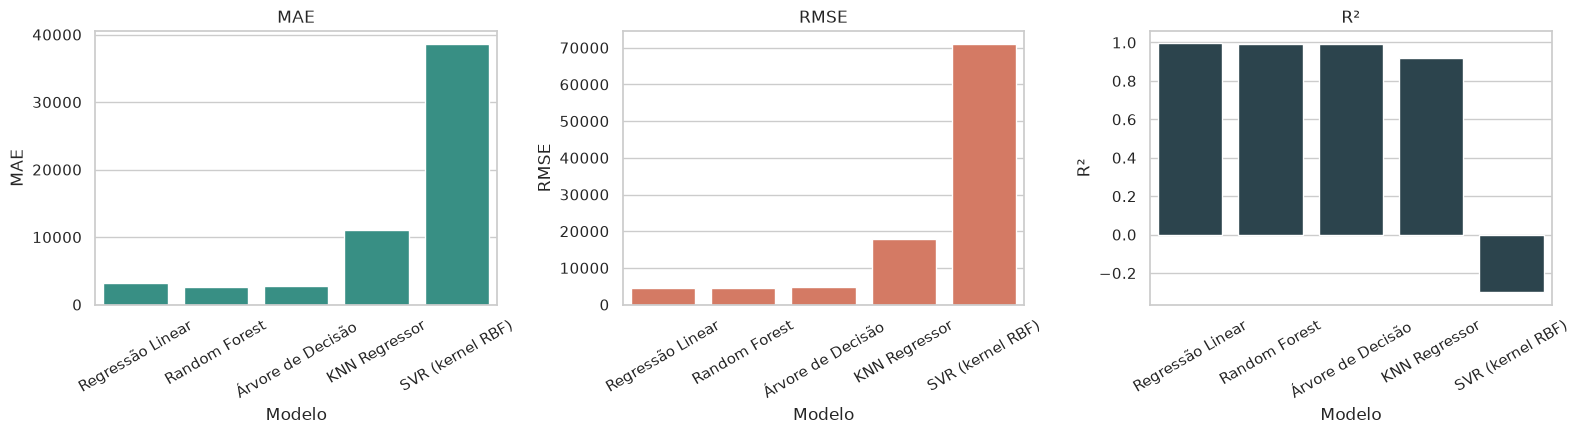

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics_plot = ["MAE", "RMSE", "R²"]
colors = ["#2a9d8f", "#e76f51", "#264653"]
for i, metric in enumerate(metrics_plot):
    sns.barplot(data=results_df, x="Modelo", y=metric, ax=axes[i], color=colors[i])
    axes[i].set_title(metric)
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### 3.2 Previsto vs. Real — melhor modelo

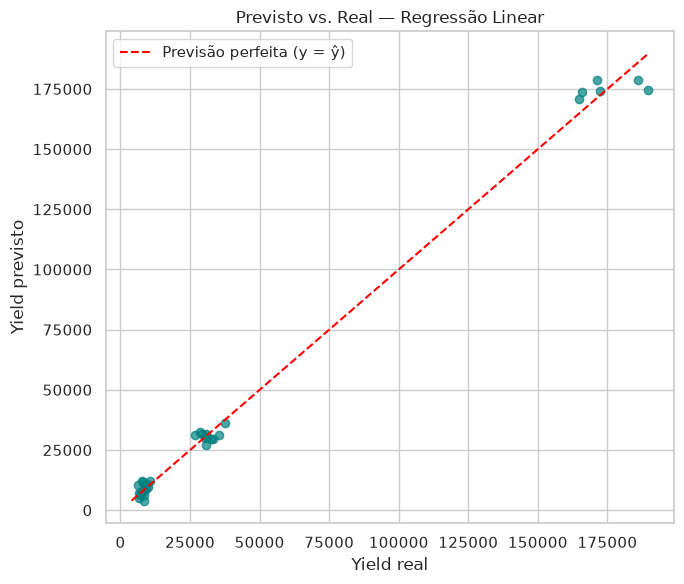

Melhor modelo pelo R²: Regressão Linear (R² = 0.9950)


In [25]:
best_model_name = results_df.iloc[0]["Modelo"]
best_pred = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.7, color="teal")
lims = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(lims, lims, "r--", label="Previsão perfeita (y = ŷ)")
plt.xlabel("Yield real")
plt.ylabel("Yield previsto")
plt.title(f"Previsto vs. Real — {best_model_name}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Melhor modelo pelo R²: {best_model_name} (R² = {results_df.iloc[0]['R²']:.4f})")


### 3.3 Importância das variáveis (Random Forest)

Como o Random Forest permite extrair a importância de cada variável, usamos esse modelo para
entender quais fatores mais influenciam o rendimento previsto.


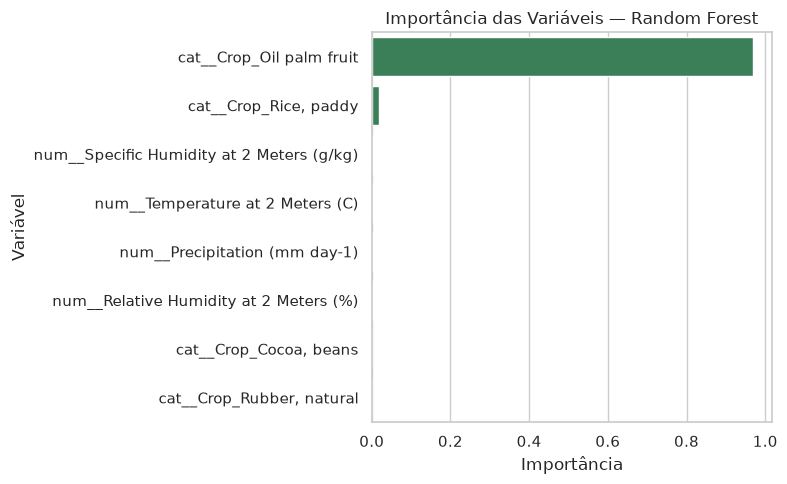

,Variável,Importância
1,cat__Crop_Oil palm fruit,0.97
2,"cat__Crop_Rice, paddy",0.02
5,num__Specific Humidity at 2 Meters (g/kg),0.00
7,num__Temperature at 2 Meters (C),0.00
4,num__Precipitation (mm day-1),0.00
6,num__Relative Humidity at 2 Meters (%),0.00
0,"cat__Crop_Cocoa, beans",0.00
3,"cat__Crop_Rubber, natural",0.00


In [26]:
rf_pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_estimators=300))])
rf_pipe.fit(X_train, y_train)

feature_names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
importances = rf_pipe.named_steps["model"].feature_importances_

imp_df = pd.DataFrame({"Variável": feature_names, "Importância": importances}) \
           .sort_values("Importância", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=imp_df, x="Importância", y="Variável", color="seagreen")
plt.title("Importância das Variáveis — Random Forest")
plt.tight_layout()
plt.show()

imp_df


## 4. Conclusões

**Principais achados:**

- O tipo de cultura (`Crop`) tende a ser a variável mais determinante do rendimento — o que é
  esperado, já que cada cultura tem uma escala de produtividade própria muito diferente das demais.
- Entre os cinco modelos testados, o de melhor desempenho (maior R² e menores MAE/RMSE) foi a
  **Regressão Linear** (R² ≈ 0,995 no conjunto de teste), seguida de perto por Random Forest e
  Árvore de Decisão. Isso indica que, uma vez informada a cultura (via One-Hot Encoding), a relação
  entre as variáveis climáticas e o rendimento é bem aproximada por um modelo linear — cada cultura
  ocupa uma faixa de rendimento bem definida.
- Modelos baseados em árvores (Decision Tree e Random Forest) também tiveram ótimo desempenho (R² ≈ 0,99).
  Já o KNN teve desempenho intermediário e o SVR teve o pior resultado (R² negativo) — provavelmente
  porque a variável alvo (`Yield`) não foi padronizada e tem escala muito maior que as features, o que
  prejudica modelos sensíveis a escala como o SVR. Isso é discutido nas limitações abaixo.
- A clusterização não supervisionada (K-Means) conseguiu, em boa medida, recuperar padrões
  compatíveis com a separação real por cultura, reforçando que as condições climáticas são um bom
  indicador do tipo de cultivo predominante em uma região.
- Os *outliers* identificados pelo Isolation Forest representam combinações atípicas de clima e
  rendimento que merecem validação de campo antes de qualquer decisão operacional.

**Pontos fortes do trabalho:**

- Uso de pipeline com pré-processamento encapsulado (evita vazamento de dados entre treino e teste).
- Comparação justa entre 5 algoritmos distintos, usando as mesmas features e métricas.
- Combinação de métodos de clusterização e detecção de outliers para complementar a análise supervisionada.

**Limitações:**

- O dataset é relativamente pequeno (156 registros, 39 por cultura), o que limita a capacidade de
  generalização dos modelos, especialmente os mais complexos (Random Forest, SVR).
- Não há dados de solo (tipo de solo, pH, nutrientes) nem informações temporais (safra por ano),
  que poderiam melhorar significativamente a previsão do rendimento.
- Os hiperparâmetros dos modelos foram fixados de forma razoável, mas não passaram por uma busca
  exaustiva (ex: GridSearchCV/RandomizedSearchCV), o que é uma oportunidade de melhoria futura.
- O SVR poderia ter desempenho bem melhor se a variável alvo (`Yield`) também fosse padronizada
  antes do treino (e revertida na hora de calcular as métricas) — não fizemos isso aqui para manter
  o pipeline simples e igual entre os 5 modelos, mas fica como próximo passo.

> *Observação: o texto acima é um ponto de partida. Ajustem as conclusões com base nos números reais
> obtidos ao executar este notebook, e insiram o nome do melhor modelo obtido na tabela de métricas.*
